In [8]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

In [9]:
# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
# Number of rows and columns
print("Shape:", df.shape)

# Display the first 5 rows
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
# List all column names
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [11]:
# Count missing values per column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
# Overview: columns, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [13]:
# Convert TotalCharges to numeric; invalid entries (blank strings) become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check missing values again
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

# Inspect the affected rows
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing values in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


Those customers are new and have not not paid abything yet which is why they do not have an entry in the Total chares column. This leads to the column having the "wrong" datatype (string instead of float).

In [15]:
# Customers with tenure = 0 have not been billed yet -> TotalCharges is logically 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify that no missing values remain
print("Missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

Missing values in TotalCharges: 0


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


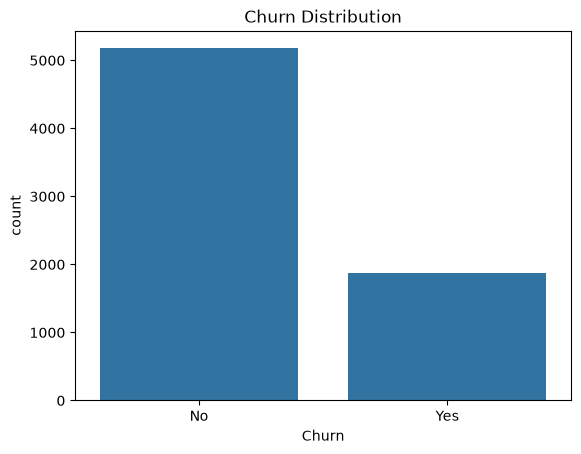

In [16]:
# Absolute count of churned vs. retained customers
print(df["Churn"].value_counts())

# Relative share in percent
print(df["Churn"].value_counts(normalize=True) * 100)

# Visualize the target distribution
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.show()

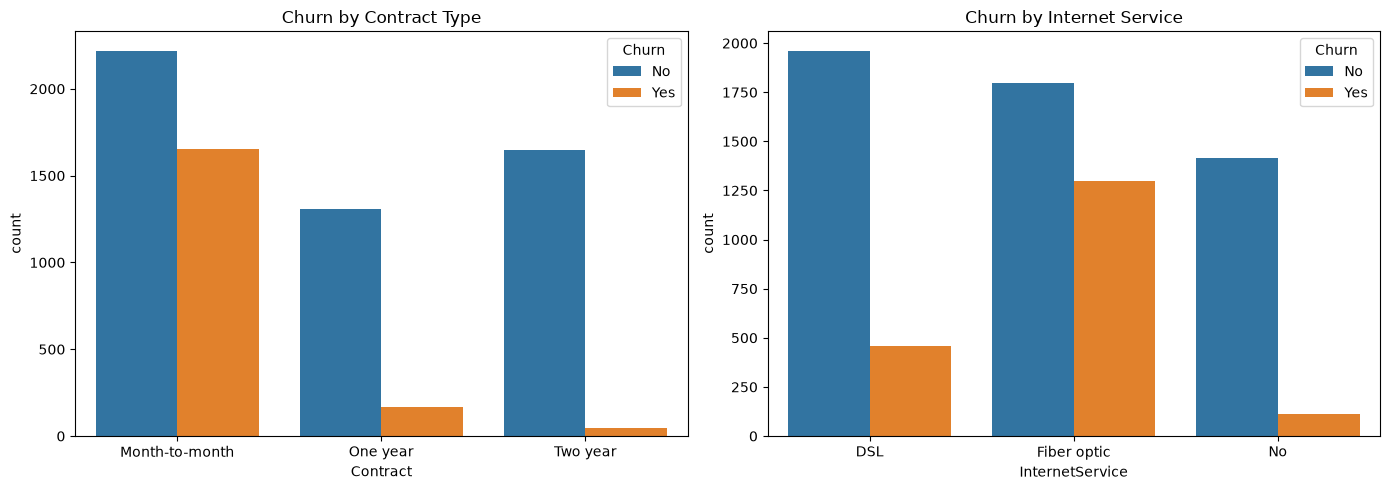

In [17]:
# --- Categorical features: churn count per category ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="Contract", hue="Churn", data=df, ax=axes[0])
axes[0].set_title("Churn by Contract Type")

sns.countplot(x="InternetService", hue="Churn", data=df, ax=axes[1])
axes[1].set_title("Churn by Internet Service")

plt.tight_layout()
plt.show()

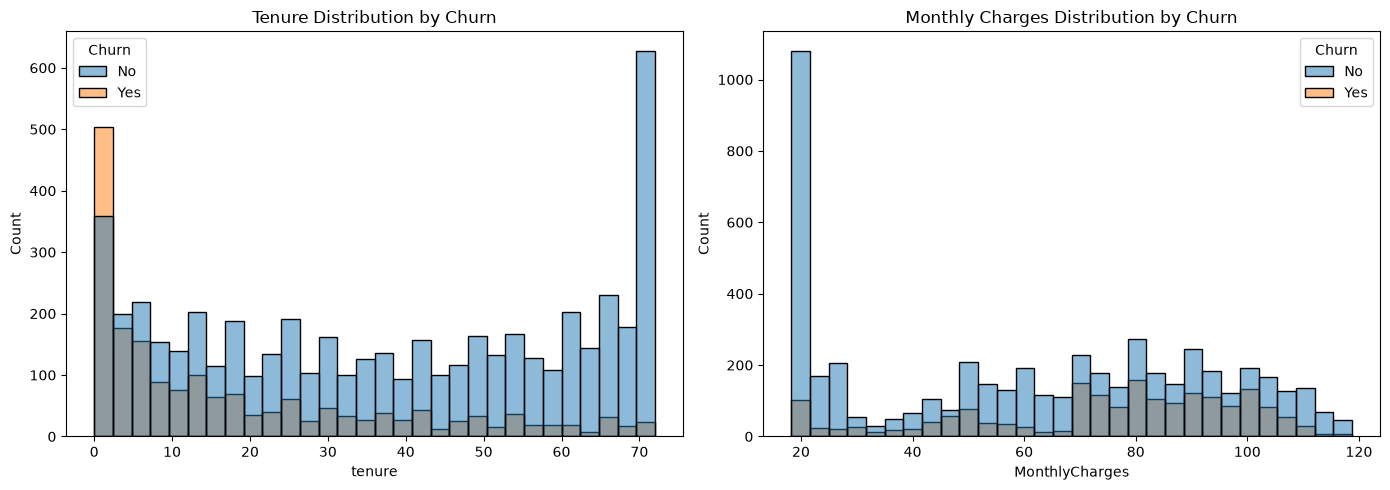

In [18]:
# --- Numerical features: distribution split by churn ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0])
axes[0].set_title("Tenure Distribution by Churn")

sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=axes[1])
axes[1].set_title("Monthly Charges Distribution by Churn")

plt.tight_layout()
plt.show()

In [19]:
# Drop customerID - it is a unique identifier with no predictive value
df = df.drop("customerID", axis=1)

print("Shape after dropping customerID:", df.shape)

Shape after dropping customerID: (7043, 20)


In [20]:
# --- 1. Binary Yes/No columns -> 1/0 (including the target 'Churn') ---
binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
for col in binary_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0})

# --- 2. Gender -> 1/0 ---
df["gender"] = df["gender"].map({"Male": 1, "Female": 0})

# --- 3. One-hot encode all remaining categorical columns ---
df = pd.get_dummies(df, dtype=int)

print("Shape after encoding:", df.shape)
df.head()

Shape after encoding: (7043, 41)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,1,0,0,1,0,0,0,0,1,0


In [21]:
# --- Separate features (X) and target (y) ---
X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (7043, 40)
Target shape: (7043,)


In [22]:
# --- Split into training (80%) and test (20%) sets ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% for testing
    stratify=y,          # keep the same churn ratio in both sets
    random_state=42      # reproducible results
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Churn rate train:", round(y_train.mean() * 100, 1), "%")
print("Churn rate test:", round(y_test.mean() * 100, 1), "%")

Training set: (5634, 40)
Test set: (1409, 40)
Churn rate train: 26.5 %
Churn rate test: 26.5 %


In [23]:
# --- Scale features ---
scaler = StandardScaler()

# Learn mean and std from training data only, then scale it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to the test data (no fitting = no data leakage)
X_test_scaled = scaler.transform(X_test)

In [24]:
# --- Step 4: Train the KNN model ---
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [25]:
# --- Step 5: Make predictions on the test set ---
y_pred = knn.predict(X_test_scaled)

# Core metrics
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))

Accuracy:  0.749
Precision: 0.53
Recall:    0.495


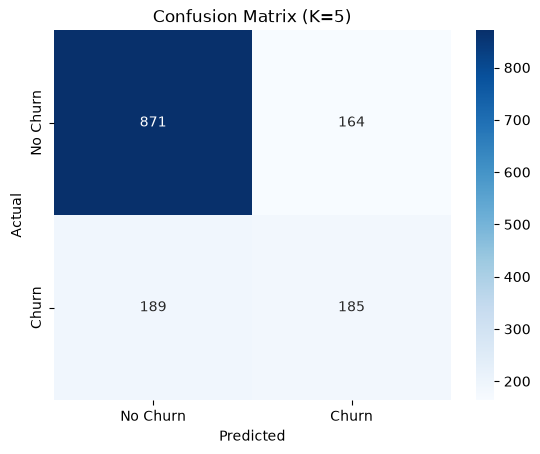

              precision    recall  f1-score   support

    No Churn       0.82      0.84      0.83      1035
       Churn       0.53      0.49      0.51       374

    accuracy                           0.75      1409
   macro avg       0.68      0.67      0.67      1409
weighted avg       0.74      0.75      0.75      1409



In [26]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn", "Churn"],
            yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (K=5)")
plt.show()

# Full classification report
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

In [27]:
# --- Step 6: Compare different K values ---
k_values = [1, 3, 5, 7, 9, 11, 15]
results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)

    results.append({
        "K": k,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3)
    })

# Collect results in a table
results_df = pd.DataFrame(results)
print(results_df)

    K  Accuracy  Precision  Recall
0   1     0.708      0.452   0.479
1   3     0.746      0.521   0.532
2   5     0.749      0.530   0.495
3   7     0.751      0.532   0.516
4   9     0.757      0.543   0.527
5  11     0.768      0.568   0.524
6  15     0.767      0.564   0.545


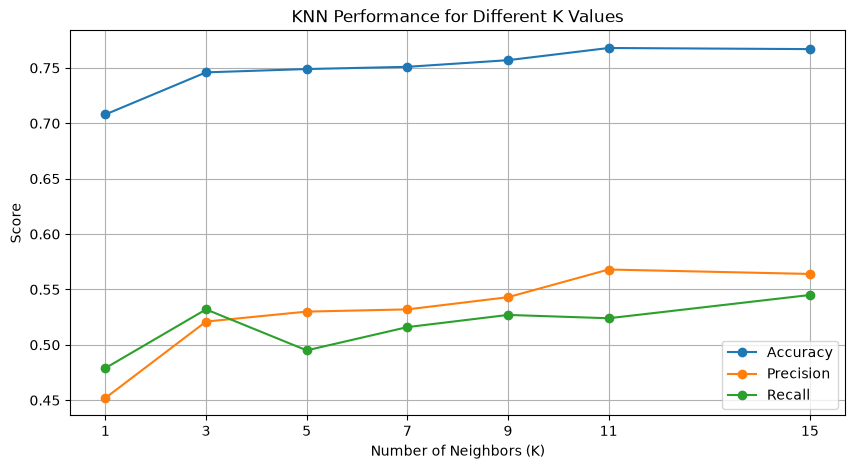

In [28]:
# Visualize metrics across K values
plt.figure(figsize=(10, 5))
plt.plot(results_df["K"], results_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(results_df["K"], results_df["Precision"], marker="o", label="Precision")
plt.plot(results_df["K"], results_df["Recall"], marker="o", label="Recall")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.title("KNN Performance for Different K Values")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

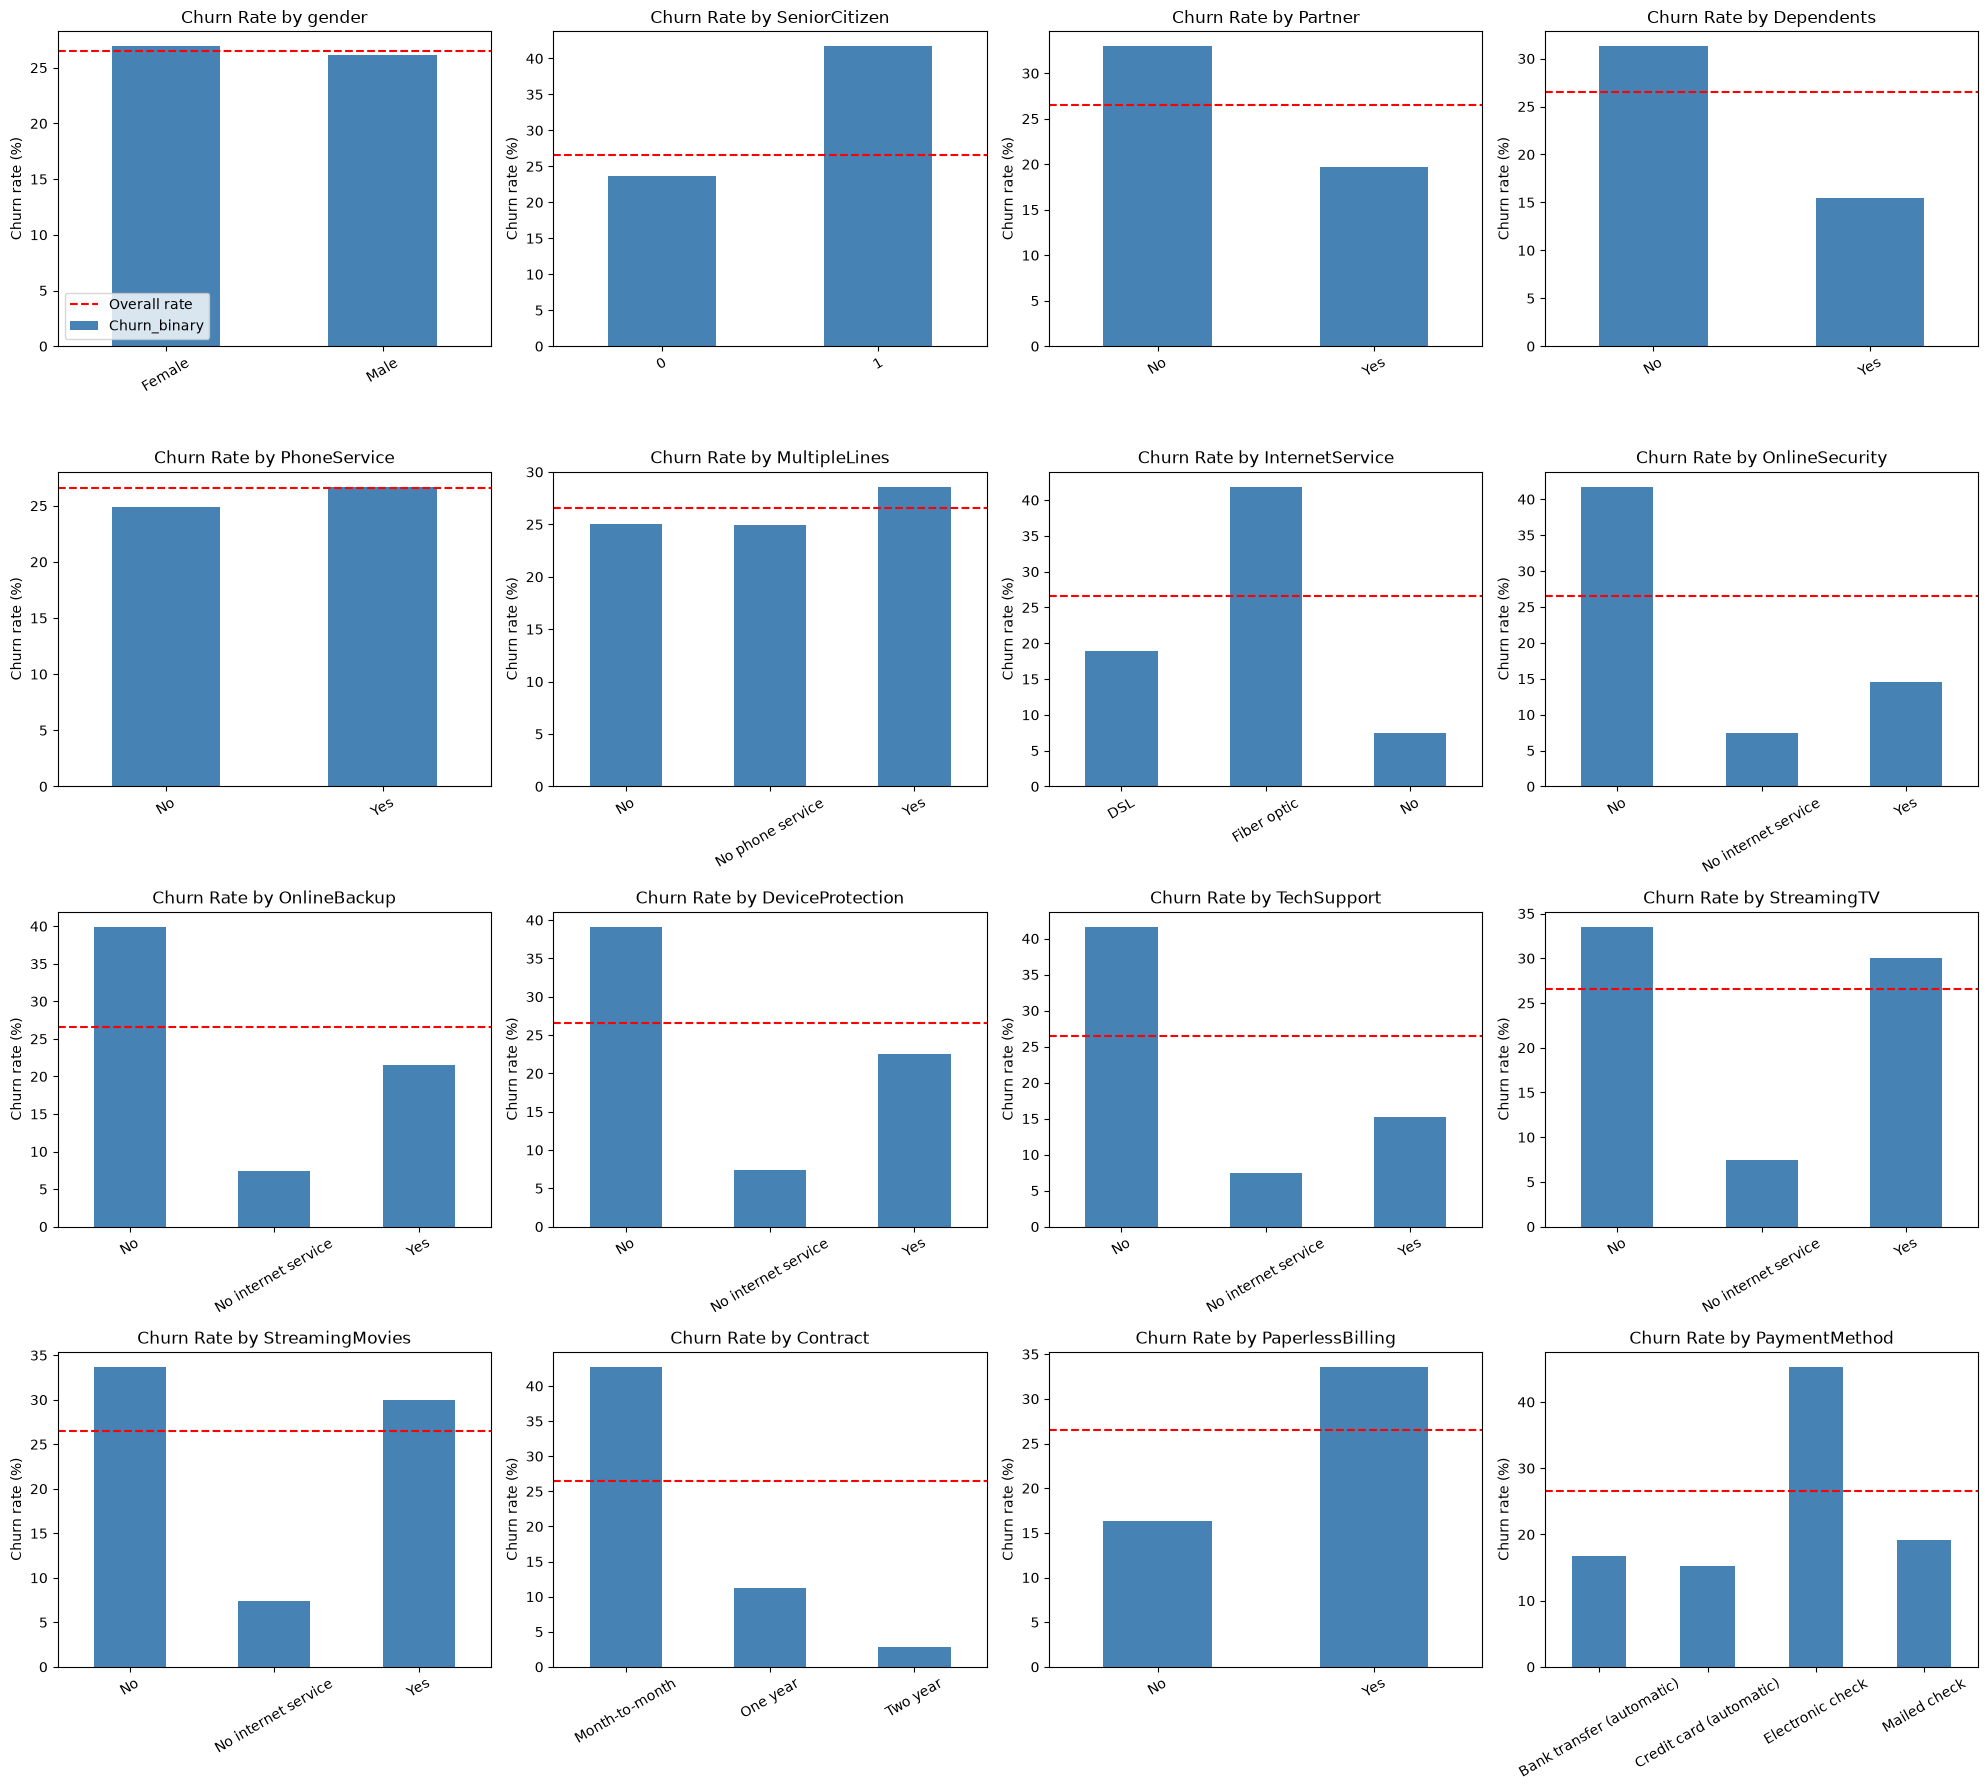

In [29]:
# Reload raw data for readable category labels
df_raw = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df_raw["Churn_binary"] = (df_raw["Churn"] == "Yes").astype(int)

# All categorical features (SeniorCitizen is stored as 0/1 but is categorical)
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents",
            "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
            "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
            "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

overall_rate = df_raw["Churn_binary"].mean() * 100

# Plot churn rate per category for every feature (4x4 grid)
fig, axes = plt.subplots(4, 4, figsize=(20, 18))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    churn_rate = df_raw.groupby(col)["Churn_binary"].mean() * 100
    churn_rate.plot(kind="bar", ax=axes[i], color="steelblue")
    axes[i].axhline(overall_rate, color="red", linestyle="--", label="Overall rate")
    axes[i].set_title(f"Churn Rate by {col}")
    axes[i].set_ylabel("Churn rate (%)")
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=30)

axes[0].legend()
plt.tight_layout()
plt.show()

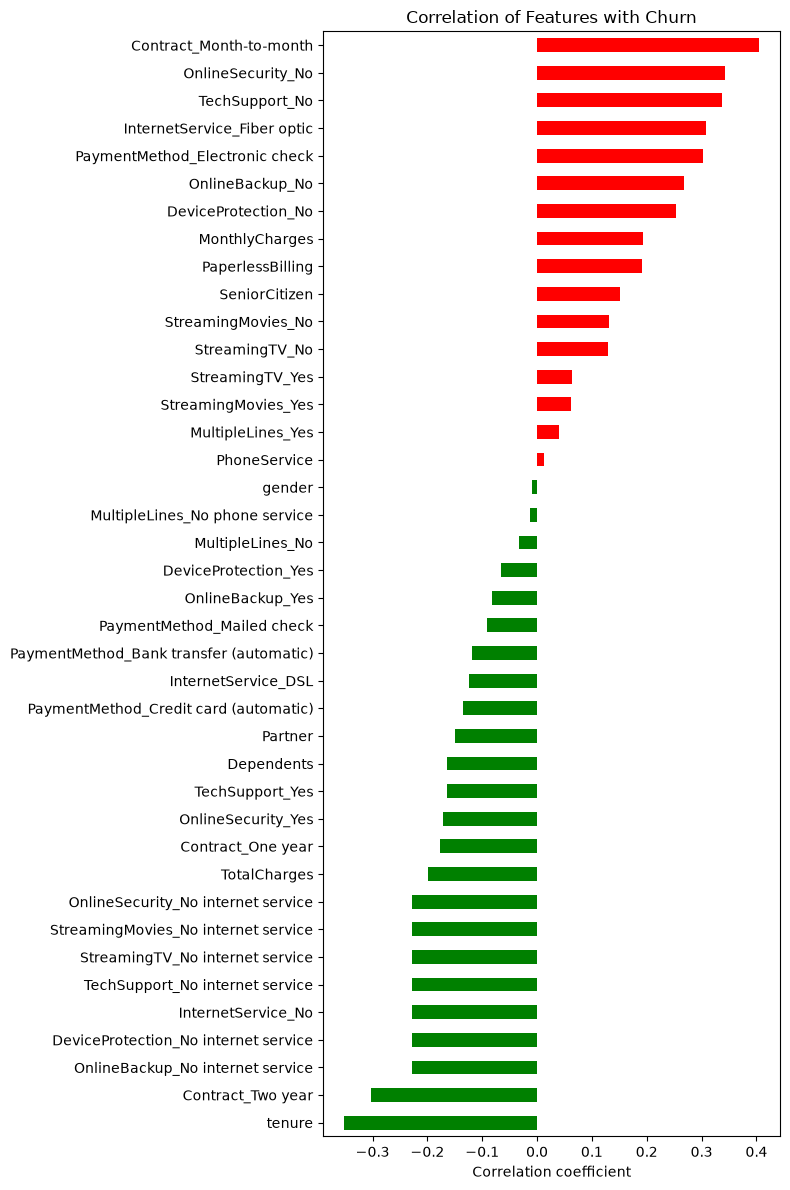

In [30]:
# Correlation of every (encoded) feature with Churn, sorted
corr = df.corr()["Churn"].drop("Churn").sort_values()

plt.figure(figsize=(8, 12))
corr.plot(kind="barh", color=["red" if c > 0 else "green" for c in corr])
plt.title("Correlation of Features with Churn")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

## Summary
### 1. Data Exploration Findings 
- the dataset contains 7,043 customers and 21 columns 
- total charges was stored as a text because of blank entries. These belonged to customers with a tenure of 0 months who had not been billed yet, so the missing values filled with 0 istead of the median 
- the target is imabalanced - 73,5% of customers did not churn and 26.5% churned. A naive model that always predicts no chrun would therefore already reach 73% accuracy while detecting 0 chruns. this makes accuracy alone a misleading metric 

### 2. Model Performance 
- with k=5 the model reached 74.9% accuracy, 53% precision and 49.5% recall
- testing k values from 1 to 15 showed that k=1 performs worst which indicates overfitting
- k=11 and k=15 perform almost identically in accuracy and precision. I chose k=15 because it achieves the highest recall which matters most for the business. Missing a churner is more costly than a false alarm 
- final model (k=15): 76.7% accuracy; 56.4& precision; 54.5% recall
- shows that the model adds real value by identifying more than half of all curners 

### 3. Most important features
- contract & tenure: these are the two strongest predictors. Month-to-moth customers churn at roughly 43% compared to 11% for one year and 3% for two year contracts 
- add-on services: cutsomers without online security or tech support churn at 42% compared to 15% for those who have them 
- InternetService: fiber optic customers chrun at 42%, DSL customers at 19%; customers without internet service are the most loyal group 

### 4. Recommendations 
- Incentivize longer contracts: Offer discounts or upgrades to month-to-month customers who switch to a one- or two-year contract
- Promote add-on services
- Use the model as an early-warning system

### 5. Limitations 
- accuracy is only slightly above the 73% baseline and only half of the churners get detected 
- important drivers of churn such as competitor offers, service quality or customer satisfaction are not included 
- only 26.5% of customers churned, so the model sees far more non-churn examples and tends to miss churners 





## Approach 
- Data exploration: loaded the dataset, checked shape, data types and missing values, and analysed the target distribution and key features with visualizations
- Data cleaning: converted TotalCharges to numeric, filled the hidden missing values with 0 and dropped customerID as it has no predictive value
- Encoding: mapped binary Yes/No columns (including the target Churn) to 1/0 and applied one-hot encoding to all categorical columns with more than two categories, so that no artificial order is introduced
- Train-test split: split the data into 80% training and 20% test data, using stratify to keep the churn ratio equal in both sets and random_state=42 for reproducibility
- Scaling: standardized all features with StandardScaler, because KNN is distance-based and features with large values (e.g. TotalCharges) would otherwise dominate. The scaler was fitted on the training data only to avoid data leakage
- Modeling: trained a KNN classifier with K=5 and evaluated it with accuracy, precision, recall, a confusion matrix and a classification report
- Optimization: tested K values of 1, 3, 5, 7, 9, 11 and 15 and selected the best K based on recall, since detecting churners is the main business goal
- Feature analysis: compared churn rates across all categorical features and ranked all features by their correlation with churn